# 01 — Preprocessing Data TextScope

**Proyek:** TextScope — Klasifikasi Emosi Bahasa Indonesia + Evaluasi Lintas Domain
**PJ:** Yuhanidz (Koordinator Data) · **Minggu 10** (Fondasi: kunci data)

> **Format file mentah dataset utama:** `Tweet<TAB>Label` (dipisah TAB, tanpa tanda kutip). Kolom Label dibuang dari teks; label diambil dari nama file dan dicocokkan dengan kolom Label.

Notebook ini menggantikan/memverifikasi `src/download_data.py` dan menghasilkan tiga file di `data/processed/`:

| File | Isi |
|---|---|
| `emosi_gabungan.csv` | Semua baris dataset utama (6 file digabung, label dari nama file), **tanpa** dibuang apa pun |
| `emosi_bersih.csv` | Dataset utama setelah dibersihkan, tanpa duplikat dan tanpa teks berlabel konflik |
| `emot_lintas.csv` | EmoT (IndoNLU) 5 kelas, label dipetakan ke skema utama, **khusus uji lintas domain** (bukan untuk latih) |

**Alur:** muat data → gabung → bersihkan teks (+ anonimisasi) → dedup & buang label konflik → petakan label EmoT → cek tumpang tindih utama vs EmoT → validasi → simpan.

> Split train/valid/test adalah tugas Linda. Sel split di bagian akhir bersifat **opsional** dan mati secara default (`MAKE_SPLIT = False`).

## 1. Konfigurasi

In [14]:
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd

# --- Lokasi proyek (jalan dari root repo atau dari folder notebooks/) ---
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW_UTAMA = ROOT / "data" / "raw" / "emosi_opini_publik"
RAW_EMOT  = ROOT / "data" / "raw" / "emot"
OUT_DIR   = ROOT / "data" / "processed"
FIG_DIR   = ROOT / "reports" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Dataset utama: nama file -> label ---
FILE_UTAMA = {
    "AngerData.csv":   "anger",
    "FearData.csv":    "fear",
    "JoyData.csv":     "joy",
    "LoveData.csv":    "love",
    "NeutralData.csv": "neutral",
    "SadData.csv":     "sad",
}
LABEL_UTAMA = ["anger", "fear", "joy", "love", "sad", "neutral"]

# --- EmoT (IndoNLU) -> skema utama ---
FILE_EMOT = ["train_preprocess.csv", "valid_preprocess.csv", "test_preprocess.csv"]
LABEL_EMOT = ["anger", "fear", "joy", "love", "sad"]          # tanpa neutral
PEMETAAN_EMOT = {"anger": "anger", "fear": "fear", "love": "love",
                 "happy": "joy", "sadness": "sad"}

# --- Opsi ---
DROP_OVERLAP_EMOT = True   # buang teks EmoT yang juga ada di dataset utama (hindari kebocoran lintas domain)
MAKE_SPLIT = False         # True hanya kalau Linda belum menyiapkan split
SEED = 42

print("Root proyek :", ROOT)
print("Dataset utama ada :", RAW_UTAMA.exists(), "| EmoT ada :", RAW_EMOT.exists())

Root proyek : c:\Users\yuhanidz\project-sistem-cerdas
Dataset utama ada : True | EmoT ada : True


## 2. Fungsi bantu

In [15]:
def baca_csv(path):
    """Baca CSV dengan beberapa kemungkinan encoding."""
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Gagal membaca {path}")


def deteksi_kolom_teks(df):
    """Cari kolom teks: nama umum dulu, kalau tidak ada pakai kolom string terpanjang."""
    for c in ["tweet", "text", "teks", "Tweet", "Text", "content", "comment", "sentence"]:
        if c in df.columns:
            return c
    obj = df.select_dtypes(include=["object", "string"])
    if obj.empty:
        raise ValueError(f"Tidak ada kolom teks. Kolom: {list(df.columns)}")
    return obj.apply(lambda s: s.astype(str).str.len().mean()).idxmax()


# --- Pola pembersihan & anonimisasi (aturan kerja no. 6 di panduan) ---
RE_PLACEHOLDER = re.compile(r"\[(?:USERNAME|URL|RT|HASHTAG)\]", re.I)
RE_URL     = re.compile(r"https?://\S+|www\.\S+", re.I)
RE_MENTION = re.compile(r"@\w+")
RE_PHONE   = re.compile(r"(?<!\d)(?:\+?62|0)8\d[\d\-\s]{7,12}\d")
RE_NIM     = re.compile(r"(?<!\d)\d{9,10}(?!\d)")
RE_REPEAT  = re.compile(r"([A-Za-z])\1{2,}")      # 'senaaang' -> 'senaang'
RE_SPASI   = re.compile(r"\s+")


def bersihkan_teks(s):
    """Pembersihan ringan. Huruf besar/kecil TIDAK diubah (tokenizer transformer yang menangani)."""
    if pd.isna(s):
        return ""
    s = unicodedata.normalize("NFKC", str(s))
    s = RE_PLACEHOLDER.sub(" ", s)
    s = RE_URL.sub(" ", s)
    s = RE_MENTION.sub(" ", s)
    s = RE_PHONE.sub(" ", s)
    s = RE_NIM.sub(" ", s)
    s = RE_REPEAT.sub(r"\1\1", s)
    return RE_SPASI.sub(" ", s).strip()


def kunci_dedup(s):
    """Kunci pembanding duplikat: huruf kecil + spasi dirapikan."""
    return s.str.lower().str.replace(RE_SPASI, " ", regex=True).str.strip()


def bersihkan_dan_dedup(df, nama):
    """
    df punya kolom: text, label.
    Langkah: bersihkan teks -> buang kosong -> buang teks berlabel konflik (semua barisnya)
             -> buang duplikat (sisakan 1).
    Mengembalikan (df_bersih, log_langkah).
    """
    log = [("awal", len(df))]
    d = df.copy()
    d["text"] = d["text"].map(bersihkan_teks)

    d = d[d["text"].str.len() > 0].copy()
    log.append(("buang teks kosong", len(d)))

    d["_key"] = kunci_dedup(d["text"])

    n_label = d.groupby("_key")["label"].nunique()
    konflik = n_label[n_label > 1].index
    d_konflik = d[d["_key"].isin(konflik)]
    d = d[~d["_key"].isin(konflik)].copy()
    log.append((f"buang label konflik ({len(konflik)} teks unik)", len(d)))

    d = d.drop_duplicates(subset="_key", keep="first").copy()
    log.append(("buang duplikat", len(d)))

    d = d.drop(columns="_key").reset_index(drop=True)
    print(f"[{nama}]")
    for langkah, n in log:
        print(f"  {langkah:<45} -> {n:>7,}")
    return d, pd.DataFrame(log, columns=["langkah", "jumlah_baris"]), d_konflik

## 3. Dataset utama — muat & gabung (`emosi_gabungan.csv`)

In [16]:
def baca_tsv_teks_label(path, label_harapan):
    """
    File mentah dataset utama berformat 'Tweet<TAB>Label' (dipisah TAB).
    Teks boleh mengandung koma dan tanda kutip, jadi baris dipisah manual pada TAB TERAKHIR
    (bukan read_csv). Kolom Label dibuang dari teks dan dicocokkan dengan label dari nama file.
    """
    for enc in ("utf-8", "utf-8-sig", "latin-1"):
        try:
            with open(path, encoding=enc) as f:
                baris = f.read().splitlines()
            break
        except UnicodeDecodeError:
            continue

    header = None
    if baris and baris[0].strip().lower().replace("\t", " ").startswith("tweet"):
        header, baris = baris[0], baris[1:]

    teks, tanpa_tab, beda_label = [], [], []
    for b in baris:
        if not b.strip():
            continue
        if "\t" not in b:
            tanpa_tab.append(b); continue
        t, lab = b.rsplit("\t", 1)
        if lab.strip().lower() != label_harapan:
            beda_label.append((t, lab)); continue
        teks.append(t.strip())

    if tanpa_tab:
        print(f"   ! {len(tanpa_tab)} baris tanpa TAB dilewati, contoh: {tanpa_tab[0][:60]!r}")
    if beda_label:
        print(f"   ! {len(beda_label)} baris berlabel BERBEDA dari nama file dilewati, contoh: {beda_label[0]!r}")
    return header, pd.DataFrame({"text": teks})


frames = []
for fname, label in FILE_UTAMA.items():
    header, df = baca_tsv_teks_label(RAW_UTAMA / fname, label)
    print(f"{fname:<18} baris={len(df):>6,}  header: {header!r}  contoh: {df['text'].iloc[0][:60]!r}")
    frames.append(pd.DataFrame({
        "text": df["text"].astype("string"),
        "label": label,
        "source": fname,
    }))

gabungan = pd.concat(frames, ignore_index=True)
print("\nTotal baris gabungan:", f"{len(gabungan):,}")
print("Teks kosong/NaN     :", int(gabungan["text"].isna().sum() + (gabungan["text"].str.strip() == "").sum()))
gabungan["label"].value_counts().reindex(LABEL_UTAMA)

AngerData.csv      baris= 1,135  header: 'Tweet\tLabel'  contoh: 'pagi2 udah di buat emosi :)'
FearData.csv       baris=   911  header: 'Tweet\tLabel'  contoh: 'trs barusan dia reach out aku trs minta tolong buat bantu pr'
JoyData.csv        baris= 1,275  header: 'Tweet\tLabel'  contoh: 'dipeluk enak nih'
LoveData.csv       baris=   760  header: 'Tweet\tLabel'  contoh: 'suka banget kata2, "kebenaran hanya menurut selera kalian sa'
NeutralData.csv    baris= 2,002  header: 'Tweet\tLabel'  contoh: 'pengabdian yang terpuji meskipun terlihat biasa'
SadData.csv        baris= 1,022  header: 'Tweet\tLabel'  contoh: 'akibat dari telat bangun, anak ikut bangun dan dapur dan rum'

Total baris gabungan: 7,105
Teks kosong/NaN     : 0


label
anger      1135
fear        911
joy        1275
love        760
sad        1022
neutral    2002
Name: count, dtype: int64

In [17]:
gabungan.to_csv(OUT_DIR / "emosi_gabungan.csv", index=False, encoding="utf-8")
gabungan.head()

,text,label,source
0,pagi2 udah di buat emosi :),anger,AngerData.csv
1,"kok stabilitas negara, memange 10 thn negara t...",anger,AngerData.csv
2,dah lah emosi mulu liat emyu,anger,AngerData.csv
3,"aib? bodoh benar! sebelum kata aib itu muncul,...",anger,AngerData.csv
4,dih lu yg nyebelin bego,anger,AngerData.csv


## 4. Dataset utama — bersihkan, dedup, buang label konflik (`emosi_bersih.csv`)

In [18]:
bersih, log_utama, konflik_utama = bersihkan_dan_dedup(gabungan[["text", "label"]], "dataset utama")

print("\nContoh teks berlabel konflik (dibuang):")
konflik_utama.sort_values("text").head(6)[["text", "label"]]

[dataset utama]
  awal                                          ->   7,105
  buang teks kosong                             ->   7,105
  buang label konflik (11 teks unik)            ->   7,082
  buang duplikat                                ->   7,031

Contoh teks berlabel konflik (dibuang):


,text,label
2447,enak dong,joy
5586,enak dong,neutral
2388,"kabar gembira untuk kita semua, kulit manggis ...",joy
4878,"kabar gembira untuk kita semua, kulit manggis ...",neutral
1518,kaget kan lo,fear
5379,kaget kan lo,neutral


In [19]:
bersih.to_csv(OUT_DIR / "emosi_bersih.csv", index=False, encoding="utf-8")
log_utama

,langkah,jumlah_baris
0,awal,7105
1,buang teks kosong,7105
2,buang label konflik (11 teks unik),7082
3,buang duplikat,7031


## 5. EmoT — petakan label, bersihkan, siapkan uji lintas domain (`emot_lintas.csv`)

Pemetaan label: `happy → joy`, `sadness → sad`. EmoT **tidak punya** kelas `neutral`.
Placeholder `[USERNAME]` / `[URL]` dibuang oleh `bersihkan_teks`.

In [20]:
frames_emot = []
for fname in FILE_EMOT:
    df = baca_csv(RAW_EMOT / fname)
    kol_teks = deteksi_kolom_teks(df)
    assert "label" in df.columns, f"{fname}: kolom 'label' tidak ditemukan. Kolom: {list(df.columns)}"
    print(f"{fname:<22} baris={len(df):>6,}  kolom teks: '{kol_teks}'")
    frames_emot.append(pd.DataFrame({
        "text": df[kol_teks].astype("string"),
        "label": df["label"].astype(str).str.strip().str.lower(),
    }))

emot_mentah = pd.concat(frames_emot, ignore_index=True)

print("\nLabel asli EmoT:", sorted(emot_mentah["label"].unique()))
tak_dikenal = set(emot_mentah["label"]) - set(PEMETAAN_EMOT)
assert not tak_dikenal, f"Label EmoT tidak dikenal: {tak_dikenal} -> tambahkan ke PEMETAAN_EMOT"

emot_mentah["label"] = emot_mentah["label"].map(PEMETAAN_EMOT)
emot, log_emot, konflik_emot = bersihkan_dan_dedup(emot_mentah, "EmoT")

train_preprocess.csv   baris= 3,521  kolom teks: 'tweet'
valid_preprocess.csv   baris=   440  kolom teks: 'tweet'
test_preprocess.csv    baris=   440  kolom teks: 'tweet'

Label asli EmoT: ['anger', 'fear', 'happy', 'love', 'sadness']
[EmoT]
  awal                                          ->   4,401
  buang teks kosong                             ->   4,401
  buang label konflik (1 teks unik)             ->   4,399
  buang duplikat                                ->   4,379


### Cek tumpang tindih dataset utama ↔ EmoT
Teks yang sama di kedua dataset membuat evaluasi lintas domain terlalu optimis, jadi dilaporkan dan (opsional) dibuang.

In [21]:
kunci_utama = set(kunci_dedup(bersih["text"]))
kunci_emot  = kunci_dedup(emot["text"])
overlap = kunci_emot.isin(kunci_utama)
print(f"Teks EmoT yang juga ada di dataset utama: {int(overlap.sum()):,} dari {len(emot):,}")

if DROP_OVERLAP_EMOT and overlap.any():
    emot = emot[~overlap].reset_index(drop=True)
    print(f"Dibuang. Sisa EmoT: {len(emot):,} baris")

emot.to_csv(OUT_DIR / "emot_lintas.csv", index=False, encoding="utf-8")
emot["label"].value_counts().reindex(LABEL_EMOT)

Teks EmoT yang juga ada di dataset utama: 0 dari 4,379


label
anger    1099
fear      641
joy      1009
love      636
sad       994
Name: count, dtype: int64

## 6. Validasi (gate Minggu 10)
Semua `assert` harus lolos sebelum hasil dilaporkan ke tim.

In [22]:
def validasi(df, nama, label_valid, boleh_ada_neutral):
    assert list(df.columns[:2]) == ["text", "label"], f"{nama}: kolom harus diawali text,label"
    assert df["text"].notna().all() and (df["text"].str.len() > 0).all(), f"{nama}: ada teks kosong"
    assert df["label"].isin(label_valid).all(), f"{nama}: ada label di luar {label_valid}"
    assert set(df["label"]) == set(label_valid), f"{nama}: ada kelas yang hilang"
    k = kunci_dedup(df["text"])
    assert not k.duplicated().any(), f"{nama}: masih ada duplikat"
    assert (df.assign(k=k).groupby("k")["label"].nunique() == 1).all(), f"{nama}: masih ada label konflik"
    if not boleh_ada_neutral:
        assert "neutral" not in set(df["label"]), f"{nama}: tidak boleh ada neutral"
    # Penjaga kebocoran: kata terakhir teks tidak boleh = nama labelnya sendiri
    akhir = df["text"].str.split().str[-1].str.lower().str.strip(".,!?")
    bocor = (akhir == df["label"]).mean() * 100
    assert bocor < 2, f"{nama}: {bocor:.1f}% teks berakhir dengan nama labelnya -> label bocor ke teks!"
    print(f"OK  {nama}: {len(df):,} baris, {df['label'].nunique()} kelas, teks berakhir nama label: {bocor:.2f}%")

bersih_cek = pd.read_csv(OUT_DIR / "emosi_bersih.csv")
emot_cek   = pd.read_csv(OUT_DIR / "emot_lintas.csv")
gab_cek    = pd.read_csv(OUT_DIR / "emosi_gabungan.csv")

validasi(bersih_cek, "emosi_bersih.csv", LABEL_UTAMA, boleh_ada_neutral=True)
validasi(emot_cek,   "emot_lintas.csv",  LABEL_EMOT,  boleh_ada_neutral=False)
print(f"OK  emosi_gabungan.csv: {len(gab_cek):,} baris (tidak difilter)")

# Tidak boleh ada teks yang sama antara dataset utama dan EmoT
if DROP_OVERLAP_EMOT:
    assert not set(kunci_dedup(bersih_cek["text"])) & set(kunci_dedup(emot_cek["text"])), "Masih ada overlap utama<->EmoT"
    print("OK  tidak ada overlap dataset utama <-> EmoT")

OK  emosi_bersih.csv: 7,031 baris, 6 kelas, teks berakhir nama label: 0.01%
OK  emot_lintas.csv: 4,379 baris, 5 kelas, teks berakhir nama label: 0.02%
OK  emosi_gabungan.csv: 7,105 baris (tidak difilter)
OK  tidak ada overlap dataset utama <-> EmoT


## 7. Ringkasan untuk laporan & `data/README.md`

In [23]:
ringkas = pd.DataFrame({
    "gabungan": gab_cek["label"].value_counts(),
    "bersih":   bersih_cek["label"].value_counts(),
    "emot":     emot_cek["label"].value_counts(),
}).reindex(LABEL_UTAMA).fillna(0).astype(int)
ringkas.loc["TOTAL"] = ringkas.sum()
print(ringkas, "\n")

pct = (bersih_cek["label"].value_counts(normalize=True).reindex(LABEL_UTAMA) * 100).round(1)
print("Sebaran label emosi_bersih (%):\n", pct.to_string())
print(f"\nRasio kelas terbesar : terkecil = {bersih_cek['label'].value_counts().max() / bersih_cek['label'].value_counts().min():.2f} : 1")

for nama, d in [("emosi_bersih", bersih_cek), ("emot_lintas", emot_cek)]:
    n_kata = d["text"].str.split().str.len()
    print(f"\n{nama}: kata per teks  min={n_kata.min()}  median={int(n_kata.median())}  rata2={n_kata.mean():.1f}  maks={n_kata.max()}")
    print(f"  teks sangat pendek (<=2 kata): {int((n_kata <= 2).sum()):,}")

         gabungan  bersih  emot
label                          
anger        1135    1123  1099
fear          911     905   641
joy          1275    1255  1009
love          760     754   636
sad          1022    1008   994
neutral      2002    1986     0
TOTAL        7105    7031  4379 

Sebaran label emosi_bersih (%):
 label
anger      16.0
fear       12.9
joy        17.8
love       10.7
sad        14.3
neutral    28.2

Rasio kelas terbesar : terkecil = 2.63 : 1

emosi_bersih: kata per teks  min=1  median=13  rata2=16.7  maks=59
  teks sangat pendek (<=2 kata): 286

emot_lintas: kata per teks  min=2  median=28  rata2=28.2  maks=79
  teks sangat pendek (<=2 kata): 1


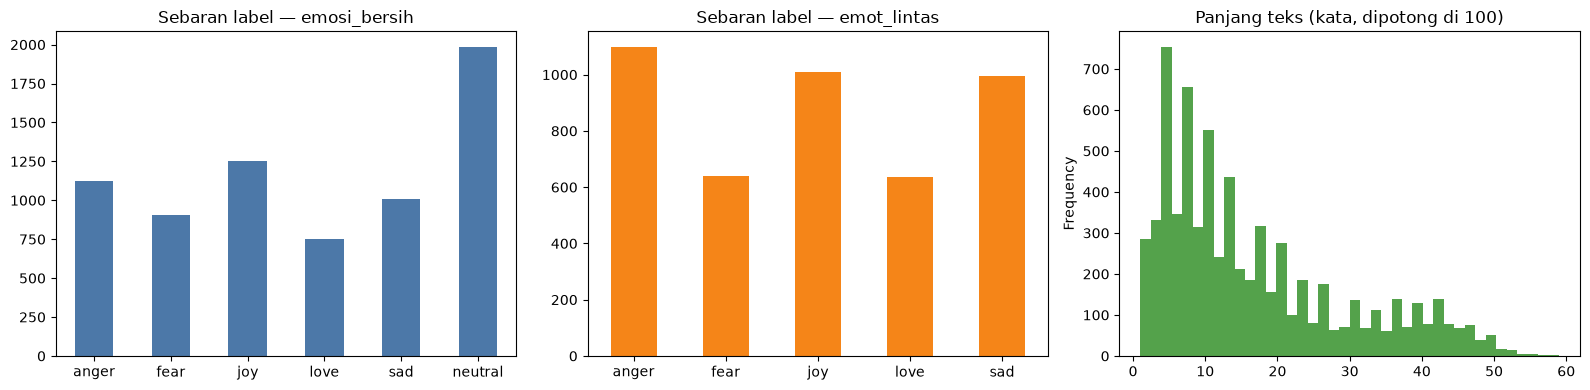

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
bersih_cek["label"].value_counts().reindex(LABEL_UTAMA).plot.bar(ax=ax[0], color="#4C78A8")
ax[0].set_title("Sebaran label — emosi_bersih"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)

emot_cek["label"].value_counts().reindex(LABEL_EMOT).plot.bar(ax=ax[1], color="#F58518")
ax[1].set_title("Sebaran label — emot_lintas"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=0)

bersih_cek["text"].str.split().str.len().clip(upper=100).plot.hist(bins=40, ax=ax[2], color="#54A24B")
ax[2].set_title("Panjang teks (kata, dipotong di 100)")

plt.tight_layout()
plt.savefig(FIG_DIR / "distribusi_preprocessing.png", dpi=150)
plt.show()

## 8.  Split train/valid/test 


dijalankan menggunakan python src/spit_data.py

## 9. Catatan untuk `data/README.md` & laporan

- **Sumber & lisensi:** Emotion Dataset from Indonesian Public Opinion (CC-BY-NC-ND 4.0); EmoT dari IndoNLU (cek lisensi di repo IndoNLU).
- **Pembersihan:** NFKC, buang placeholder `[USERNAME]`/`[URL]`, URL, mention `@`, nomor telepon & NIM (anonimisasi), huruf berulang >2 dipendekkan, spasi dirapikan. Huruf besar/kecil **tidak** diubah.
- **Dedup:** perbandingan memakai teks huruf kecil; teks berlabel ganda dibuang seluruhnya.
- **Belum dilakukan (sengaja):** normalisasi kata gaul, stemming, stopword — itu eksperimen Minggu 12 (Linda) dan dicatat di tabel percobaan.
- **Data mentah dan `data/processed/*.csv` tidak di-commit ke GitHub** (simpan di Google Drive bersama).